## Linear algebra

MATLAB was born as a matrix laboratory. Backslash solves `A*x = b`, picking a method from the matrix's structure; `cond` says how much the solution can amplify errors in `b`. LU, QR and Cholesky factor a matrix.

In [ ]:
A = [4 -2 1; -2 4 -2; 1 -2 4];  b = [11; -16; 17];
x = A \ b
fprintf('residual %.2g, cond %.4f\n', norm(A*x - b), cond(A))
[L, U, P] = lu(A);  [Q, R] = qr(A);  Rc = chol(A);
fprintf('errors: lu %.2g, qr %.2g, chol %.2g\n', norm(P*A - L*U), norm(Q*R - A), norm(Rc'*Rc - A))


x =

     1
    -2
     3



residual 0, cond 4.5292
errors: lu 0, qr 1.6e-15, chol 4.4e-16


Five equal masses joined by springs, fixed at both ends: the normal modes' squared frequencies are the eigenvalues of the stiffness matrix. With more equations than unknowns, backslash gives the least-squares solution, the same as `pinv`.

In [ ]:
K = 2*eye(5) - diag(ones(4, 1), 1) - diag(ones(4, 1), -1);
frequencies = sqrt(eig(K))'
rng(2);  t = linspace(0, 4, 30)';  y = 1 + 0.5*t - 0.3*t.^2 + 0.15*randn(30, 1);
M = [ones(30, 1), t, t.^2];
coef = (M \ y)'
same_as_pinv = norm(coef' - pinv(M)*y) < 1e-12


frequencies =

    0.5176    1.0000    1.4142    1.7321    1.9319


coef =

    0.8860    0.5886   -0.3240


same_as_pinv =

  logical

   1



The singular value decomposition $A = U \Sigma V^T$ gives the best rank-$k$ approximation of a matrix: keep the $k$ largest singular values. An image is a matrix, so a few already hold most of it.

rank 1 keeps 82.3% of the energy
rank 3 keeps 90.5% of the energy
rank 10 keeps 99.0% of the energy


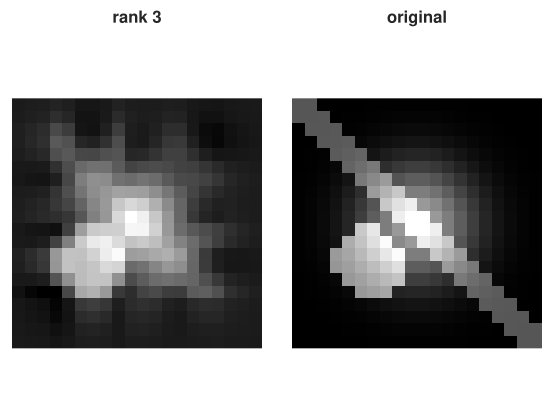

In [ ]:
figure
[gx, gy] = meshgrid(linspace(-3, 3, 20));
img = exp(-(gx.^2 + gy.^2)/2) + 0.8*((gx + 1.2).^2 + (gy - 1).^2 < 0.8) + 0.5*(abs(gx - gy) < 0.4);
[Us, S, Vs] = svd(img);  sv = diag(S);
energy = 100 * cumsum(sv.^2) / sum(sv.^2);
fprintf('rank %d keeps %.1f%% of the energy\n', [1 3 10; energy([1 3 10])'])
subplot(1, 2, 1), imagesc(Us(:, 1:3) * S(1:3, 1:3) * Vs(:, 1:3)'), axis equal off, title('rank 3')
subplot(1, 2, 2), imagesc(img), axis equal off, title('original')
colormap(gray)

*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*